# Lab 2: Show confidence and errors

To start, save a copy to your Drive (File, then Save a copy in Drive) and pick a GPU runtime (Runtime, then Change runtime type, then T4 GPU). This lab goes with Lecture 8 and Milestone 2, and in it you get a model's confidence, check whether it matches how often the model is right, and show it to people in four ways. The outputs below are from running it on a Mac, so your numbers will be a little different.

## 1. Setup

This installs anything that is missing, picks the GPU and imports the libraries. The models and the questions download later in the notebook (about 6.5 GB in total).

In [1]:
# Install anything this notebook needs that is not already installed.
# Colab already has most of these, so this cell is usually quick.
import importlib.util, subprocess, sys

needed = {"transformers": "transformers", "datasets": "datasets", "sklearn": "scikit-learn", "matplotlib": "matplotlib", "pandas": "pandas"}  # module name: pip package name
missing = [pkg for mod, pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("Installed now:", missing or "nothing, all were already there")

Installed now: nothing, all were already there


In [2]:
import torch

# Use a GPU if there is one: "cuda" on Colab, "mps" on a recent Mac, otherwise the CPU.
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Running on", device)

Running on mps


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

## 2. A classifier's confidence

The digits dataset in scikit-learn has 1,797 handwritten digits of 8 by 8 pixels. This trains two classifiers on half of them and tests them on the other half, and the highest probability from `predict_proba` is each model's confidence in its answer.

In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

digits = load_digits()
X_train, X_test, y_train, y_test, img_train, img_test = train_test_split(
    digits.data, digits.target, digits.images, test_size=0.5, random_state=0
)

classifiers = {
    "Naive Bayes": GaussianNB(),
    "Logistic regression": LogisticRegression(max_iter=5000),
}
results = {}
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    probs = clf.predict_proba(X_test)          # one probability per digit, for each test image
    pred = probs.argmax(axis=1)
    results[name] = {"confidence": probs.max(axis=1), "correct": pred == y_test, "pred": pred}
    print(f"{name}: right on {np.mean(pred == y_test):.1%} of test images, "
          f"average confidence {probs.max(axis=1).mean():.1%}")

Naive Bayes: right on 83.4% of test images, average confidence 98.8%
Logistic regression: right on 95.4% of test images, average confidence 97.2%


### Reliability diagram

A model is calibrated when its confidence matches how often it is right. For example, of the answers it gives with 80% confidence, about 80% should be right. This sorts the answers into bins by confidence and draws how many in each bin were right, so a bar below the diagonal means the model is overconfident in that bin. The expected calibration error (ECE) is the average gap between confidence and accuracy, weighted by how many answers fall in each bin, and lower is better.

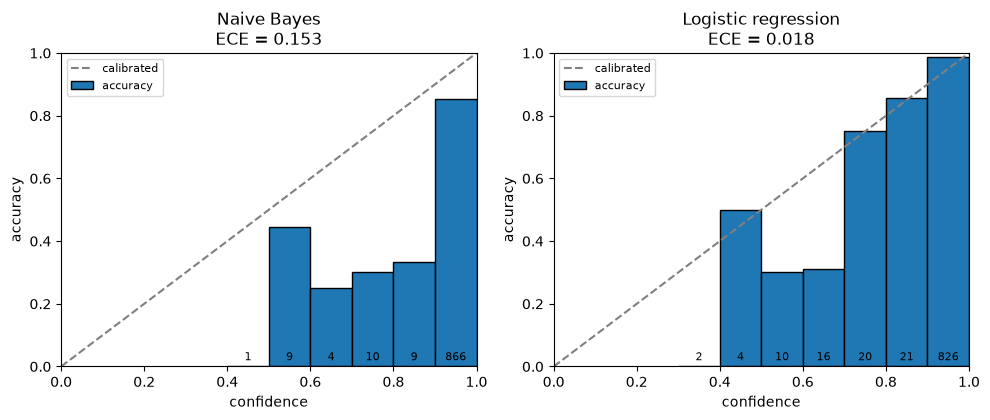

In [5]:
def reliability(confidence, correct, n_bins=10):
    """Accuracy and average confidence for each confidence bin, plus the expected calibration error."""
    confidence, correct = np.asarray(confidence), np.asarray(correct, dtype=float)
    edges = np.linspace(0, 1, n_bins + 1)
    which = np.clip(np.digitize(confidence, edges[1:-1]), 0, n_bins - 1)
    rows, ece = [], 0.0
    for b in range(n_bins):
        in_bin = which == b
        if in_bin.any():
            acc, conf = correct[in_bin].mean(), confidence[in_bin].mean()
            ece += in_bin.mean() * abs(acc - conf)
            rows.append({"from": edges[b], "to": edges[b + 1], "count": int(in_bin.sum()),
                         "accuracy": acc, "confidence": conf})
    return pd.DataFrame(rows), ece


def plot_reliability(ax, confidence, correct, title):
    table, ece = reliability(confidence, correct)
    ax.bar(table["from"], table["accuracy"], width=0.1, align="edge", edgecolor="black", label="accuracy")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="calibrated")
    for _, r in table.iterrows():
        ax.text(r["from"] + 0.05, 0.02, int(r["count"]), ha="center", fontsize=8)  # answers in the bin
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="confidence", ylabel="accuracy",
           title=f"{title}\nECE = {ece:.3f}")
    ax.legend(loc="upper left", fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, (name, r) in zip(axes, results.items()):
    plot_reliability(ax, r["confidence"], r["correct"], name)
plt.tight_layout()
plt.show()

The small numbers on the bars are how many answers fall in each bin. Naive Bayes puts almost every answer in the top bin, even the wrong ones. This is because it treats every pixel as separate evidence, so it counts the same evidence many times.

### The wrong answers

These are the wrong answers each model was most sure about. Would a person looking at the image have trusted them?

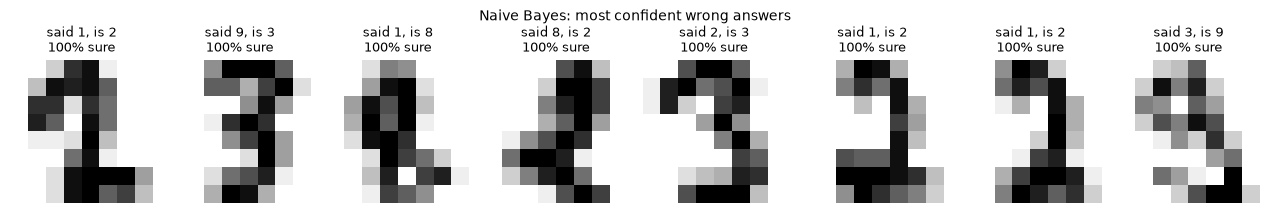

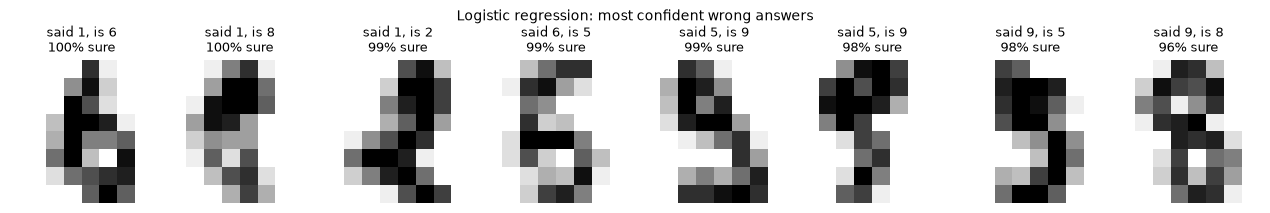

In [6]:
def show_examples(name, which, title, n=8):
    r = results[name]
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.2))
    for ax, i in zip(axes, which[:n]):
        ax.imshow(img_test[i], cmap="gray_r")
        ax.set_title(f"said {r['pred'][i]}, is {y_test[i]}\n{r['confidence'][i]:.0%} sure", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{name}: {title}", fontsize=10)
    plt.tight_layout()
    plt.show()

for name, r in results.items():
    wrong = np.where(~r["correct"])[0]
    wrong = wrong[np.argsort(-r["confidence"][wrong])]  # most confident first
    show_examples(name, wrong, "most confident wrong answers")

### Answer only when sure enough

One common design shows the answer only above some confidence and says "not sure" otherwise. The tables show how many answers each cutoff still shows and how many of those are right. A cutoff only helps if the answers with higher confidence are also right more often.

In [7]:
def cutoff_table(confidence, correct, cutoffs=(0.0, 0.5, 0.8, 0.9, 0.95, 0.99)):
    rows = []
    for c in cutoffs:
        shown = confidence >= c
        rows.append({"show if at least": f"{c:.0%}",
                     "answers shown": f"{shown.mean():.0%}",
                     "right among shown": f"{correct[shown].mean():.1%}" if shown.any() else "-",
                     "wrong answers shown": int((shown & ~correct).sum())})
    return pd.DataFrame(rows)

for name, r in results.items():
    print(name)
    display(cutoff_table(r["confidence"], r["correct"]))

Naive Bayes


,show if at least,answers shown,right among shown,wrong answers shown
0,0%,100%,83.4%,149
1,50%,100%,83.5%,148
2,80%,97%,84.8%,133
3,90%,96%,85.3%,127
4,95%,95%,85.7%,123
5,99%,93%,87.5%,104


Logistic regression


,show if at least,answers shown,right among shown,wrong answers shown
0,0%,100%,95.4%,41
1,50%,99%,95.9%,37
2,80%,94%,98.3%,14
3,90%,92%,98.7%,11
4,95%,90%,98.9%,9
5,99%,82%,99.3%,5


## 3. A language model's confidence

A language model gives a probability to every possible next token, so you can get its confidence in three ways: the probability of its answer, the probability of each token it writes, and how often it gives the same answer when you ask again. This loads Qwen2.5-1.5B-Instruct, a small open model from 2024.

In [8]:
from transformers import AutoTokenizer, AutoModelForCausalLM

def load(model_id):
    tok = AutoTokenizer.from_pretrained(model_id)
    lm = AutoModelForCausalLM.from_pretrained(
        model_id, dtype=torch.float16 if device != "cpu" else torch.float32
    ).to(device).eval()
    return tok, lm

INSTRUCT_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer, model = load(INSTRUCT_ID)
print("Loaded", INSTRUCT_ID)

Loaded Qwen/Qwen2.5-1.5B-Instruct


### 3a. The probability of its answer

This uses 200 questions from the ARC Challenge set, which are grade-school science questions with 3 to 5 choices labeled A, B, C and so on. The model answers with a letter, and its probabilities for the choice letters give its answer (the highest one) and its confidence.

In [9]:
from datasets import load_dataset

questions = load_dataset("allenai/ai2_arc", "ARC-Challenge", split="test").shuffle(seed=0).select(range(200))
LETTERS = ["A", "B", "C", "D", "E"]

def format_question(q):
    options = "\n".join(f"{LETTERS[i]}. {text}" for i, text in enumerate(q["choices"]["text"]))
    return f"{q['question']}\n\n{options}"

print(format_question(questions[0]))
print("Right answer:", LETTERS[questions[0]["choices"]["label"].index(questions[0]["answerKey"])])

A student reads the following description of a region: "It has warm summers, moderate winters, and frequent rainfall." What information does this description best provide?

A. current weather
B. weather forecast
C. general climate
D. climate changes
Right answer: C


In [10]:
def letter_confidence(tok, lm, chat=True):
    """For each question: the model's answer, its confidence, and whether it was right."""
    # Token ids for the letters. A chat model starts its reply with "A"; a base model continues "Answer:" with " A".
    letter_ids = [tok.encode(l if chat else " " + l, add_special_tokens=False)[0] for l in LETTERS]
    rows = []
    for q in questions:
        n = len(q["choices"]["text"])
        if chat:
            messages = [{"role": "user", "content": format_question(q) + "\n\nAnswer with the letter only."}]
            inputs = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)
        else:
            inputs = tok("Question: " + format_question(q) + "\nAnswer:", return_tensors="pt")
        with torch.no_grad():
            scores = lm(**inputs.to(device)).logits[0, -1].float()
        probs = torch.softmax(scores[letter_ids[:n]], dim=-1).cpu().numpy()  # only the choice letters
        right = q["choices"]["label"].index(q["answerKey"])
        rows.append({"answer": LETTERS[probs.argmax()], "confidence": probs.max(),
                     "correct": probs.argmax() == right, "scores": scores[letter_ids[:n]].cpu().numpy()})
    return pd.DataFrame(rows)

instruct = letter_confidence(tokenizer, model)
print(f"Right on {instruct['correct'].mean():.1%}, average confidence {instruct['confidence'].mean():.1%}")

Right on 72.5%, average confidence 97.0%


### Before and after instruction tuning

OpenAI reported in the GPT-4 technical report (2023) that the pre-trained GPT-4 was well calibrated and that the training after it made this worse. You can check the same thing here with Qwen2.5-1.5B, the base model before it was tuned to follow instructions, which gets each question as plain text ending in "Answer:".

Base model: right on 75.5%, average confidence 76.6%


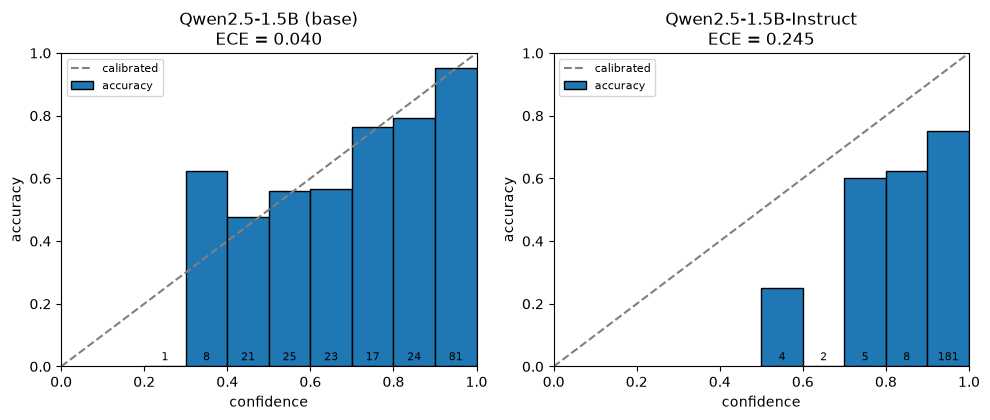

In [11]:
import gc
del model
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

base_tok, base_model = load("Qwen/Qwen2.5-1.5B")
base = letter_confidence(base_tok, base_model, chat=False)
print(f"Base model: right on {base['correct'].mean():.1%}, average confidence {base['confidence'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
plot_reliability(axes[0], base["confidence"], base["correct"], "Qwen2.5-1.5B (base)")
plot_reliability(axes[1], instruct["confidence"], instruct["correct"], "Qwen2.5-1.5B-Instruct")
plt.tight_layout()
plt.show()

del base_model
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

In the run above, the two models got about the same share of questions right (75.5% and 72.5%), but the instruct model put most of its answers above 90% confidence, while the base model's confidence stayed close to how often it was right.

### Temperature scaling

One simple fix divides the model's scores by a number T before turning them into probabilities, and a T above 1 lowers the confidence. This picks T on half of the questions and checks it on the other half, so the fix is tested on questions it was not fitted to.

Best T on the fitting half: 4.60

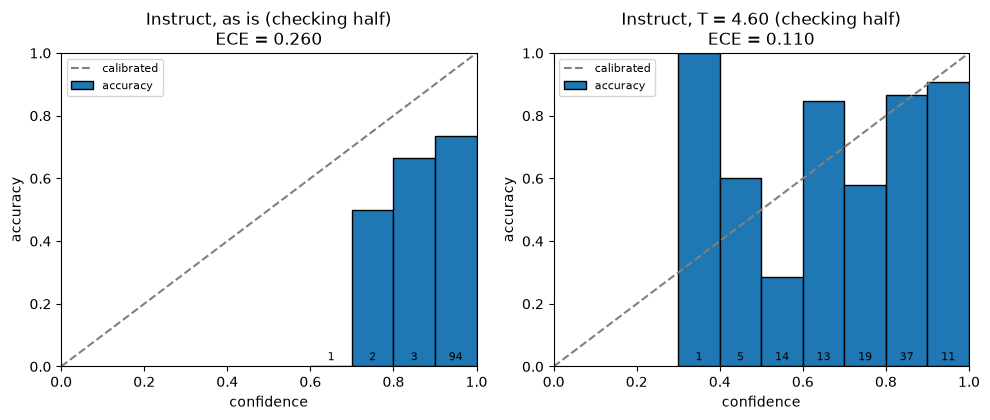

In [12]:
def softmax(z):
    z = z - z.max()
    return np.exp(z) / np.exp(z).sum()

def confidences_at(scores_list, T):
    return np.array([softmax(s / T).max() for s in scores_list])

def nll(scores_list, right, T):
    """Average negative log probability of the right answer. Lower means better probabilities."""
    return np.mean([-np.log(softmax(s / T)[r]) for s, r in zip(scores_list, right)])

right_index = [q["choices"]["label"].index(q["answerKey"]) for q in questions]
fit, check = np.arange(0, 200, 2), np.arange(1, 200, 2)   # even questions to fit T, odd ones to check it

Ts = np.linspace(0.5, 10, 96)
losses = [nll(instruct["scores"].iloc[fit], np.array(right_index)[fit], T) for T in Ts]
best_T = Ts[int(np.argmin(losses))]
print(f"Best T on the fitting half: {best_T:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
plot_reliability(axes[0], instruct["confidence"].iloc[check], instruct["correct"].iloc[check], "Instruct, as is (checking half)")
plot_reliability(axes[1], confidences_at(instruct["scores"].iloc[check], best_T), instruct["correct"].iloc[check],
                 f"Instruct, T = {best_T:.2f} (checking half)")
plt.tight_layout()
plt.show()

Temperature scaling does not change which answer the model picks, only how sure it says it is. With 100 questions in each half the bins are small, so the numbers will move around if you change the questions.

### 3b. The probability of each token

A longer answer has no single answer token, but every token the model writes still has a probability, and a low one marks a place where the model could easily have written something else. This reloads the instruct model and asks for an answer with a few facts in it.

In [13]:
tokenizer, model = load(INSTRUCT_ID)

def answer_with_probs(prompt, max_new_tokens=80):
    messages = [{"role": "user", "content": prompt}]
    inputs = tokenizer.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             output_logits=True, return_dict_in_generate=True,
                             pad_token_id=tokenizer.eos_token_id)
    new_ids = out.sequences[0, inputs["input_ids"].shape[1]:]
    tokens, probs = [], []
    for step, token_id in enumerate(new_ids):
        if token_id == tokenizer.eos_token_id:
            break
        p = torch.softmax(out.logits[step][0].float(), dim=-1)[token_id].item()
        tokens.append(tokenizer.decode([int(token_id)]))
        probs.append(p)
    return tokens, np.array(probs)

tokens, probs = answer_with_probs("In two sentences: when was Carnegie Mellon University founded, and who founded it?")
print("".join(tokens))
print()
for t, p in sorted(zip(tokens, probs), key=lambda x: x[1])[:8]:
    print(f"{p:6.1%}  {t!r}")

Carnegie Mellon University was founded in 1900 by Andrew W. Mellon and his wife, Dorothy Frances Carnegie.

  8.6%  ' Frances'
 18.8%  ' Dorothy'
 37.3%  ' Andrew'
 40.7%  ' W'
 44.3%  ' and'
 44.9%  ' his'
 56.3%  ' wife'
 67.0%  ' Carnegie'


Andrew Carnegie founded the school in 1900 as the Carnegie Technical Schools, so the founders in the answer above are wrong, and several of their names are among the least likely tokens. A low probability does not always mean an error, though. Often there are just several fine ways to word the same sentence.

### 3c. Agreement with itself

This works with any model, including ones behind an API that do not give probabilities. It asks the same question 10 times with sampling on and counts how often the answers agree.

In [14]:
def sample_answers(prompt, n=10, temperature=1.0, max_new_tokens=12):
    messages = [{"role": "user", "content": prompt}]
    inputs = tokenizer.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(device)
    with torch.no_grad():
        out = model.generate(**inputs, do_sample=True, temperature=temperature, top_p=1.0, top_k=0,
                             num_return_sequences=n, max_new_tokens=max_new_tokens,
                             pad_token_id=tokenizer.eos_token_id)
    start = inputs["input_ids"].shape[1]
    return [tokenizer.decode(row[start:], skip_special_tokens=True).strip().rstrip(".") for row in out]

torch.manual_seed(0)
for prompt in ["What is the capital of France? Answer with the name only.",
               "In what year did Joseph Weizenbaum publish his paper on ELIZA? Answer with the year only.",
               "In what year was the ACM founded? Answer with the year only."]:
    answers = pd.Series(sample_answers(prompt))
    counts = answers.value_counts()
    print(prompt)
    print(f"  most common answer: {counts.index[0]!r}, given {counts.iloc[0]} of {len(answers)} times")
    print("  all answers:", ", ".join(f"{a} ({c})" for a, c in counts.items()), "\n")

What is the capital of France? Answer with the name only.
  most common answer: 'Paris', given 10 of 10 times
  all answers: Paris (10) 



In what year did Joseph Weizenbaum publish his paper on ELIZA? Answer with the year only.
  most common answer: '1966', given 10 of 10 times
  all answers: 1966 (10) 



In what year was the ACM founded? Answer with the year only.
  most common answer: '1948', given 4 of 10 times
  all answers: 1948 (4), 1947 (3), 1940 (2), 1960 (1) 



The ELIZA paper came out in 1966 and the ACM was founded in 1947, so the most common answer for the ACM above is wrong. Agreement is not the same as being right, since a model can also give the same wrong answer most of the time. You can try `sample_answers` on the Carnegie Mellon question from 3b to see whether the founders change between answers.

## 4. Showing the uncertainty

The next cell shows one answer in four ways: a number ("62% sure"), words chosen from the number, highlighting of the tokens with low probability, and the other answers the model gave when asked again. Kim and colleagues (a Lecture 8 reading) found that answers starting with "I'm not sure, but..." made people agree with the AI less and get more answers right. Vasconcelos and colleagues found that highlighting the tokens a code model found least likely did not help programmers, while highlighting what they would likely edit did.

In [15]:
import html

def in_words(p):
    # These cutoffs are a design choice. Check them against your own reliability diagram.
    if p >= 0.9:
        return "I'm confident that"
    if p >= 0.6:
        return "I think that"
    return "I'm not sure, but maybe"

def show_four_ways(question, tokens, probs, alternatives, low=0.5):
    answer = "".join(tokens)
    confidence = float(np.prod(probs) ** (1 / len(probs)))  # average per-token probability (geometric mean)
    highlighted = "".join(
        f'<span style="background: rgba(255, 140, 0, {min(1, (1 - p) * 1.2):.2f})" title="{p:.0%}">{html.escape(t)}</span>'
        if p < low else html.escape(t)
        for t, p in zip(tokens, probs)
    )
    counts = pd.Series(alternatives).value_counts()
    alt_list = "".join(f"<li>{html.escape(a)} <span style='color:#666'>({c} of {len(alternatives)})</span></li>" for a, c in counts.items())
    box = "border:1px solid #ccc; border-radius:8px; padding:10px 12px; margin:6px 0; font: 14px/1.5 sans-serif"
    display(HTML(f"""
      <div style="max-width:720px">
        <p style="font: 600 14px sans-serif">{html.escape(question)}</p>
        <div style="{box}"><b>Number</b><br>{html.escape(answer)} <span style="color:#666">({confidence:.0%} sure)</span></div>
        <div style="{box}"><b>Words</b><br>{in_words(confidence)} {html.escape(answer[0].lower() + answer[1:])}</div>
        <div style="{box}"><b>Highlighting</b> <span style="color:#666">(hover for each token's probability)</span><br>{highlighted}</div>
        <div style="{box}"><b>Alternatives</b><ul style="margin:4px 0">{alt_list}</ul></div>
      </div>"""))

question = "In what year was the ACM founded? Answer in one short sentence."
tokens, probs = answer_with_probs(question, max_new_tokens=30)
# For the alternatives, ask for the year only, so answers group by what they say rather than how they say it
alternatives = sample_answers("In what year was the ACM founded? Answer with the year only.")
show_four_ways(question, tokens, probs, alternatives)

In the run above, the answer was right (1947), but when asked again the model said 1940 more often than 1947. Which of the four boxes, if any, would have made you check the year before repeating it? For a multiple-choice answer you can use the answer probability from 3a instead of the average per token, and for a model behind an API you can use the agreement from 3c.

## Exercises

These help with Milestone 2 (Make it understandable), where you build a prototype that shows people when the AI might be wrong and test it with 2 people.

**Exercise 1.** Write 20 questions from your group that have a right answer you can check (for example, rules a club organizer would look up), and turn them into multiple-choice questions. Get the model's confidence with `letter_confidence` and draw the reliability diagram. Since 20 questions is only a few, use `n_bins=5`. Is the model over- or underconfident on your group's questions?

In [16]:
# Exercise 1: your code here

**Exercise 2.** Pick a cutoff below which your prototype says "not sure", and run `cutoff_table` on your questions. How many answers would carry the warning, and how many wrong answers would still be shown without one? For your group, is it worse to show a warning on an answer that is right, or to show a wrong answer without a warning?

In [17]:
# Exercise 2: your code here

**Exercise 3.** Change `in_words` so that each phrase matches how often answers in that range were right in your reliability diagram. For example, do not say "I'm confident" for a range where the model was right only 70% of the time.

In [18]:
# Exercise 3: your code here

**Exercise 4.** Pick two of the four displays for one of your tool's real outputs and build both. Then plan how you will test them with 2 people from your group, with and without the display and in swapped orders (Lecture 7). Which wrong answers will you plant, and what will you record for each person? A notebook like this one is fine as a prototype for Milestone 2.

In [19]:
# Exercise 4: your code here